# Proxy de largeur de trottoir — étape 1 : rectangles et couverture du sol

Objectif de ce notebook :

1. Charger les segments piétons (`step1_all_segments.gpkg`).
2. Séparer les segments selon le tag `highway` :
   - **liste A** : segments qui passent par le traitement géométrique (rectangle autour du segment) ;
   - **liste B** : segments auxquels on attribue directement un score, type par type.
3. Construire pour chaque segment de la liste A un rectangle de **longueur = longueur du segment** et de **largeur choisie**.
4. Croiser avec la couche de couverture du sol (attribut `vegetation`) :
   - **analyse 1** : dans quelles catégories de couverture du sol tombent les segments → histogramme ;
   - **extraction** : tout ce qui est contenu dans chaque rectangle (surface par catégorie).

Les sections marquées **À COMPLÉTER** sont des points d'entrée pour la suite (calcul du proxy).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)

## 1. Paramètres

Tout ce qui se règle est ici.

- `LARGEUR_M` est la **largeur totale** du rectangle (le segment est au centre, donc `LARGEUR_M / 2` de chaque côté).
- `METHODE` :
  - `"buffer_plat"` (par défaut) : buffer à extrémités plates. Pour un segment droit c'est exactement un rectangle ; pour un segment courbe, la bande suit la courbe (longueur = longueur du segment).
  - `"rectangle"` : vrai rectangle orienté selon la corde début → fin du segment. Plus simple, mais déborde/rate de la surface sur les segments courbes (environ 8 % des segments ont une corde < 90 % de leur longueur).
- `HIGHWAY_A_TRAITER` : liste A (traitement géométrique).
- `SCORES_DIRECTS` : liste B, `{valeur highway: score}`. Mettre le score que tu veux ; `None` = pas encore décidé.

In [2]:
# --- Chemins ---
SEGMENTS_PATH = Path("/Users/maximiliantrique/Documents/GitHub/projet_pieton_gg/Data/output/walk/GG/step-1/step1_all_segments.gpkg")   # .gpkg ou .parquet, les deux marchent
SEGMENTS_LAYER = None                                    # nom de couche du gpkg si plusieurs couches

VEG_PATH = Path("/Users/maximiliantrique/Documents/GitHub/projet_pieton_gg/Data/input/attributs/GG/canopee/SIPV_MN_CARTO_GG.gpkg")              # gpkg de couverture du sol
VEG_LAYER = None
VEG_ATTR = "vegetation"                                  # attribut de classification

OUTPUT_DIR = Path("/Users/maximiliantrique/Documents/GitHub/projet_pieton_gg/outputs/walk/largeur_trottoir")

# --- Géométrie ---
CRS_METRIQUE = 2056        # CH1903+ / LV95, en mètres
LARGEUR_M = 6.0            # largeur totale du rectangle (m)
METHODE = "buffer_plat"    # "buffer_plat" ou "rectangle"

# --- Filtrage highway ---
# Liste A : segments qui subissent le traitement géométrique
HIGHWAY_A_TRAITER = [
 
    "footway",
]

# Liste B : score attribué d'emblée, par type
SCORES_DIRECTS = {
    "steps": None,
    "platform": None,
    "corridor": None,
    "service": None
   
}

# --- Divers ---
ECHANTILLON = None   # ex. 20000 pour tester vite ; None = tous les segments
SEED = 0

## 2. Chargement des segments

In [3]:
def lire_couche(path, layer=None):
    path = Path(path)
    if path.suffix.lower() == ".parquet":
        return gpd.read_parquet(path)
    return gpd.read_file(path, layer=layer)

seg = lire_couche(SEGMENTS_PATH, SEGMENTS_LAYER).to_crs(CRS_METRIQUE)

if ECHANTILLON is not None and ECHANTILLON < len(seg):
    seg = seg.sample(ECHANTILLON, random_state=SEED)

# longueur recalculée dans le CRS métrique (la colonne `length` d'origine est la même)
seg["seg_len_m"] = seg.length
print(f"{len(seg):,} segments, CRS = {seg.crs.to_string()}")
seg[["segment_id", "highway", "walk_class", "walk_role", "seg_len_m"]].head()

536,734 segments, CRS = EPSG:2056


,segment_id,highway,walk_class,walk_role,seg_len_m
0,000000,footway,walk_dedicated,dedicated,5.920195
1,000001,track,walk_track,dedicated,50.000000
2,000002,track,walk_track,dedicated,50.000000
3,000003,track,walk_track,dedicated,50.000000
4,000004,track,walk_track,dedicated,50.000000


## 3. Répartition des types `highway` et vérification des listes

In [4]:
repart = (
    seg.groupby("highway", dropna=False)
       .agg(n_segments=("segment_id", "size"), longueur_km=("seg_len_m", lambda s: s.sum() / 1000))
       .sort_values("n_segments", ascending=False)
)

def liste_de(hw):
    if hw in HIGHWAY_A_TRAITER:
        return "A (géométrie)"
    if hw in SCORES_DIRECTS:
        return "B (score direct)"
    return "non assigné"

repart["liste"] = [liste_de(h) for h in repart.index]
display(repart)

doublons = set(HIGHWAY_A_TRAITER) & set(SCORES_DIRECTS)
assert not doublons, f"Ces types sont dans les deux listes : {doublons}"

non_assignes = repart.index[repart["liste"] == "non assigné"].tolist()
if non_assignes:
    print("⚠ Types highway dans aucune liste (ignorés) :", non_assignes)

,n_segments,longueur_km,liste
highway,,,
service,146983,3710.190692,B (score direct)
track,96374,4147.338581,non assigné
footway,85953,2018.581883,A (géométrie)
residential,68777,2008.151023,non assigné
path,59131,2554.241347,non assigné
unclassified,42710,1571.360175,non assigné
tertiary,24005,730.000032,non assigné
steps,3576,28.712613,B (score direct)
living_street,3572,98.202679,non assigné


⚠ Types highway dans aucune liste (ignorés) : ['track', 'residential', 'path', 'unclassified', 'tertiary', 'living_street', 'pedestrian']


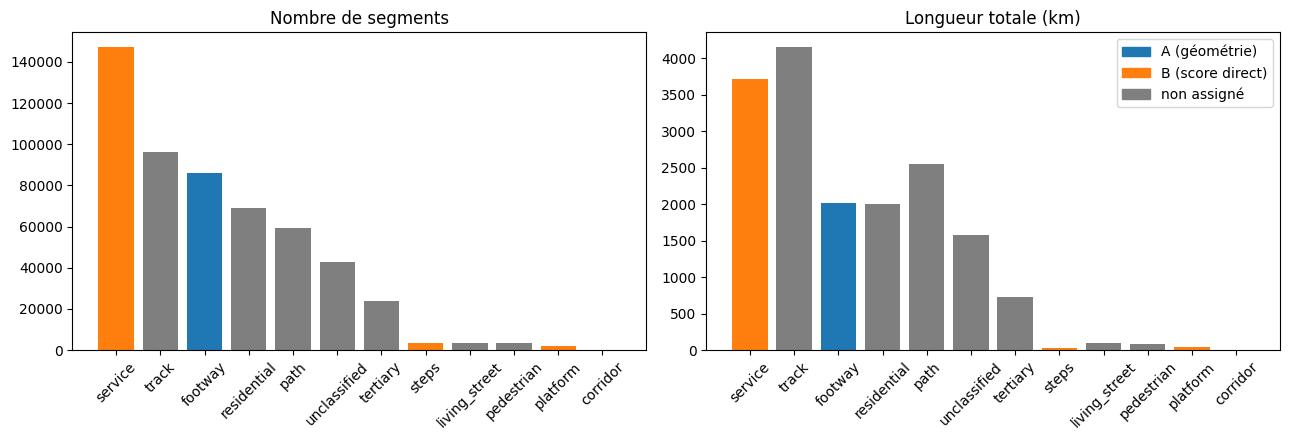

In [5]:
couleurs = {"A (géométrie)": "tab:blue", "B (score direct)": "tab:orange", "non assigné": "tab:gray"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col, titre in zip(axes, ["n_segments", "longueur_km"], ["Nombre de segments", "Longueur totale (km)"]):
    ax.bar(repart.index.astype(str), repart[col], color=[couleurs[l] for l in repart["liste"]])
    ax.set_title(titre)
    ax.tick_params(axis="x", rotation=45)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in couleurs.values()]
axes[1].legend(handles, couleurs.keys())
plt.tight_layout()
plt.show()

## 4. Séparation liste A / liste B

In [6]:
seg_A = seg[seg["highway"].isin(HIGHWAY_A_TRAITER)].copy()

seg_B = seg[seg["highway"].isin(SCORES_DIRECTS.keys())].copy()
seg_B["score_largeur"] = seg_B["highway"].map(SCORES_DIRECTS)

print(f"Liste A (géométrie)   : {len(seg_A):,} segments")
print(f"Liste B (score direct): {len(seg_B):,} segments "
      f"(dont {seg_B['score_largeur'].isna().sum():,} sans score encore défini)")

Liste A (géométrie)   : 85,953 segments
Liste B (score direct): 152,813 segments (dont 152,813 sans score encore défini)


## 5. Construction des rectangles

Fonction vectorisée (shapely 2), rapide même sur plusieurs centaines de milliers de segments.

In [7]:
def construire_rectangles(gdf, largeur, methode="buffer_plat"):
    # Retourne un GeoDataFrame de polygones (mêmes index/attributs que gdf).
    demi = largeur / 2.0
    geoms = gdf.geometry.values

    if methode == "buffer_plat":
        polys = shapely.buffer(geoms, demi, cap_style="flat", join_style="mitre", mitre_limit=2.0)

    elif methode == "rectangle":
        p0 = shapely.get_coordinates(shapely.get_point(geoms, 0))
        p1 = shapely.get_coordinates(shapely.get_point(geoms, -1))
        d = p1 - p0
        n = np.hypot(d[:, 0], d[:, 1])
        n[n == 0] = np.nan                       # segments fermés / dégénérés
        u = d / n[:, None]                       # direction unitaire
        v = np.column_stack([-u[:, 1], u[:, 0]]) * demi   # normale * demi-largeur
        coins = np.stack([p0 + v, p1 + v, p1 - v, p0 - v, p0 + v], axis=1)
        polys = shapely.polygons(coins)
        polys[np.isnan(n)] = None
    else:
        raise ValueError(f"methode inconnue : {methode}")

    out = gdf.drop(columns="geometry").copy()
    out = gpd.GeoDataFrame(out, geometry=polys, crs=gdf.crs)
    out["rect_area_m2"] = out.area
    n_vides = out.geometry.isna().sum() + out.geometry.is_empty.sum()
    if n_vides:
        print(f"⚠ {n_vides} rectangles vides (segments de longueur nulle ou fermés)")
    return out

rect_A = construire_rectangles(seg_A, LARGEUR_M, METHODE)
rect_A = rect_A[rect_A.geometry.notna() & ~rect_A.geometry.is_empty]
print(f"{len(rect_A):,} rectangles, surface médiane = {rect_A['rect_area_m2'].median():.1f} m²")

85,953 rectangles, surface médiane = 109.8 m²


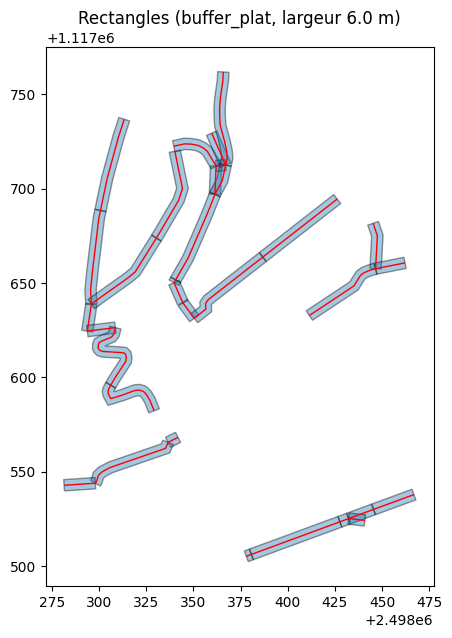

In [8]:
# Contrôle visuel sur une petite zone
centre = seg_A.geometry.iloc[0].centroid
zone = centre.buffer(150)
ax = rect_A[rect_A.intersects(zone)].plot(figsize=(7, 7), alpha=0.4, edgecolor="k")
seg_A[seg_A.intersects(zone)].plot(ax=ax, color="red", linewidth=1)
ax.set_title(f"Rectangles ({METHODE}, largeur {LARGEUR_M} m)")
ax.set_aspect("equal")
plt.show()

## 6. Chargement de la couverture du sol

In [9]:
import pyogrio

# 1. Lecture ciblée : un seul attribut, emprise des rectangles
info = pyogrio.read_info(VEG_PATH, layer=VEG_LAYER)
print(f"Couche complète : {info['features']:,} entités ({info['geometry_type']})")
bbox = tuple(rect_A.to_crs(info["crs"]).total_bounds)
veg = gpd.read_file(VEG_PATH, layer=VEG_LAYER, columns=[VEG_ATTR], bbox=bbox, use_arrow=True)
assert VEG_ATTR in veg.columns, f"Attribut '{VEG_ATTR}' absent. Colonnes : {list(veg.columns)}"

# 2. Suppression de Z / M, puis reprojection
veg = veg[veg.geometry.notna() & ~veg.geometry.is_empty]
veg["geometry"] = shapely.force_2d(veg.geometry.values)
veg = veg.to_crs(CRS_METRIQUE)

# 3. Garder seulement les polygones proches d'un rectangle (index spatial, emprises)
_, idx_veg = veg.sindex.query(rect_A.geometry.values)
veg = veg.iloc[np.unique(idx_veg)].reset_index(drop=True)

# 4. Ne réparer que les invalides
invalides = ~shapely.is_valid(veg.geometry.values)
print(f"{invalides.sum():,} géométries invalides réparées")
if invalides.any():
    veg.loc[invalides, "geometry"] = shapely.make_valid(veg.geometry.values[invalides])

veg[VEG_ATTR] = veg[VEG_ATTR].astype(str)
print(f"{len(veg):,} polygones retenus, {veg[VEG_ATTR].nunique()} catégories")
veg[VEG_ATTR].value_counts()

Couche complète : 918,363 entités (MultiPolygon Z)


/Users/maximiliantrique/Documents/GitHub/projet_pieton_gg/venv/lib/python3.11/site-packages/pyogrio/core.py:279: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_read_info(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/contextlib.py:137: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return next(self.gen)


443 géométries invalides réparées
55,893 polygones retenus, 27 catégories


vegetation
Urbain dense                            18194
Urbain diffus                           10828
végétation urbaine                       9519
Chemin                                   4141
Végétation arborée perturbée             3215
Forêts fermées de feuillus               2324
Cultures et prairies intensives          2175
Forêts ouvertes                          1873
Prairies extensives                      1135
Ruisseau                                  532
Forêts humides                            438
Autres milieux humides                    269
Route                                     230
Chemin de fer                             218
Vigne                                     207
Rivière                                   145
Forêts fermées de conifères               105
Eaux calmes                                67
Landes                                     65
Prairies sèches                            62
Prairies d'altitudes                       52
Verger                 

## 7. Fonction d'intersection par catégorie

Pour chaque paire (géométrie, polygone de couverture) qui s'intersecte, on calcule la **longueur** (pour les segments)
ou la **surface** (pour les rectangles) de la partie commune. Résultat au format long :
`segment_id | catégorie | mesure`.

In [10]:
def intersection_par_categorie(gdf, veg, attr, mesure, id_col="segment_id"):
    # mesure = "length" (lignes) ou "area" (polygones)
    gauche = gdf[[id_col, "geometry"]].reset_index(drop=True)
    paires = gpd.sjoin(gauche, veg[[attr, "geometry"]], how="inner", predicate="intersects")
    g_geom = gauche.geometry.values[paires.index.values]
    v_geom = veg.geometry.values[veg.index.get_indexer(paires["index_right"])]
    inter = shapely.intersection(g_geom, v_geom)
    val = shapely.length(inter) if mesure == "length" else shapely.area(inter)
    res = pd.DataFrame({id_col: paires[id_col].values, attr: paires[attr].values, mesure: val})
    res = res[res[mesure] > 0]
    return res.groupby([id_col, attr], as_index=False)[mesure].sum()

veg = veg.reset_index(drop=True)

## 8. Analyse 1 — dans quelles catégories tombent les segments de la liste A ?

Un segment peut traverser plusieurs catégories. On produit deux lectures :

- **catégorie dominante** : la catégorie qui contient la plus grande part de la longueur du segment → histogramme en nombre de segments ;
- **longueur totale** par catégorie (chaque morceau de segment compté dans sa catégorie).

Les segments (ou parties) qui ne tombent dans aucun polygone sont classés `hors_couverture`.

In [11]:
long_seg = intersection_par_categorie(seg_A, veg, VEG_ATTR, "length")

# part hors couverture
couvert = long_seg.groupby("segment_id")["length"].sum()
reste = seg_A.set_index("segment_id")["seg_len_m"].sub(couvert, fill_value=0).clip(lower=0)
reste = reste[reste > 0.01]
hors = pd.DataFrame({"segment_id": reste.index, VEG_ATTR: "hors_couverture", "length": reste.values})
long_seg = pd.concat([long_seg, hors], ignore_index=True)

# catégorie dominante par segment
idx = long_seg.groupby("segment_id")["length"].idxmax()
dominante = long_seg.loc[idx, ["segment_id", VEG_ATTR]].rename(columns={VEG_ATTR: "veg_dominante"})
seg_len = seg_A.set_index("segment_id")["seg_len_m"]
dominante["part_dominante"] = (
    long_seg.loc[idx, "length"].values / seg_len.loc[dominante["segment_id"]].values
)

seg_A = seg_A.drop(columns=["veg_dominante", "part_dominante"], errors="ignore").merge(
    dominante, on="segment_id", how="left"
)
seg_A[["segment_id", "highway", "veg_dominante", "part_dominante"]].head()

,segment_id,highway,veg_dominante,part_dominante
0,000000,footway,Forêts fermées de feuillus,1.000000
1,000041,footway,Chemin,0.723497
2,000042,footway,Cultures et prairies intensives,0.660851
3,000043,footway,Chemin,0.480364
4,000044,footway,Forêts fermées de feuillus,0.533347


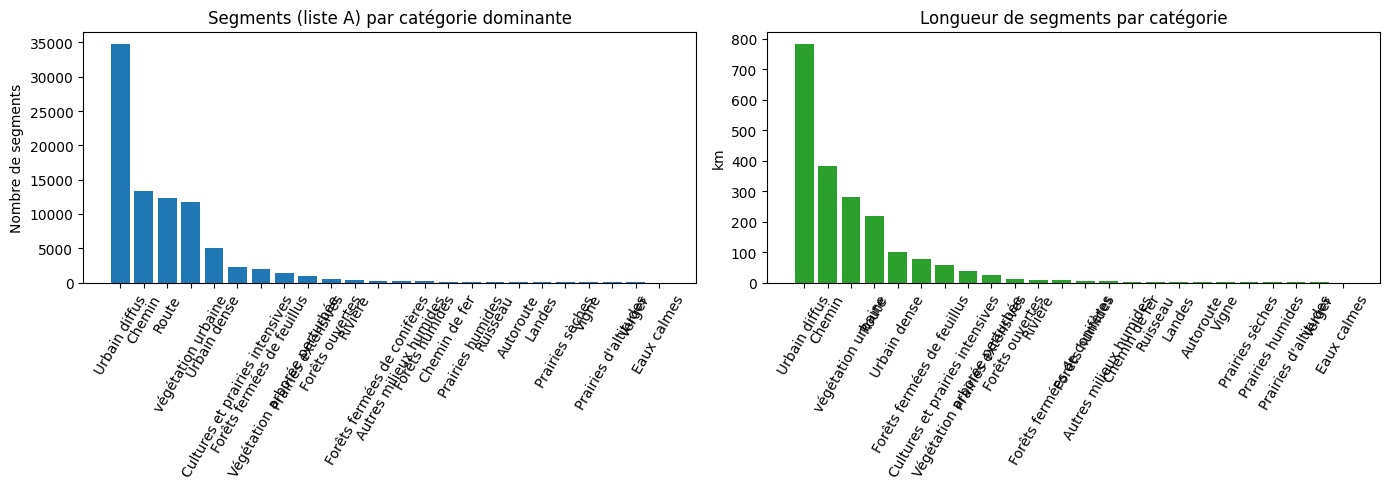

,n_segments_dominante,longueur_km,part_longueur_%
Autoroute,63,1.75,0.1
Autres milieux humides,177,4.54,0.2
Chemin,13324,380.61,18.9
Chemin de fer,143,2.94,0.1
Cultures et prairies intensives,2243,58.39,2.9
Eaux calmes,9,0.15,0.0
Forêts fermées de conifères,193,8.45,0.4
Forêts fermées de feuillus,2027,75.80,3.8
Forêts humides,175,6.41,0.3
Forêts ouvertes,496,13.11,0.6


In [12]:
hist_n = seg_A["veg_dominante"].value_counts()
hist_km = long_seg.groupby(VEG_ATTR)["length"].sum().div(1000).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(hist_n.index, hist_n.values)
axes[0].set_title("Segments (liste A) par catégorie dominante")
axes[0].set_ylabel("Nombre de segments")
axes[1].bar(hist_km.index, hist_km.values, color="tab:green")
axes[1].set_title("Longueur de segments par catégorie")
axes[1].set_ylabel("km")
for ax in axes:
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

pd.DataFrame({"n_segments_dominante": hist_n, "longueur_km": hist_km.round(2),
              "part_longueur_%": (100 * hist_km / hist_km.sum()).round(1)}).fillna(0)

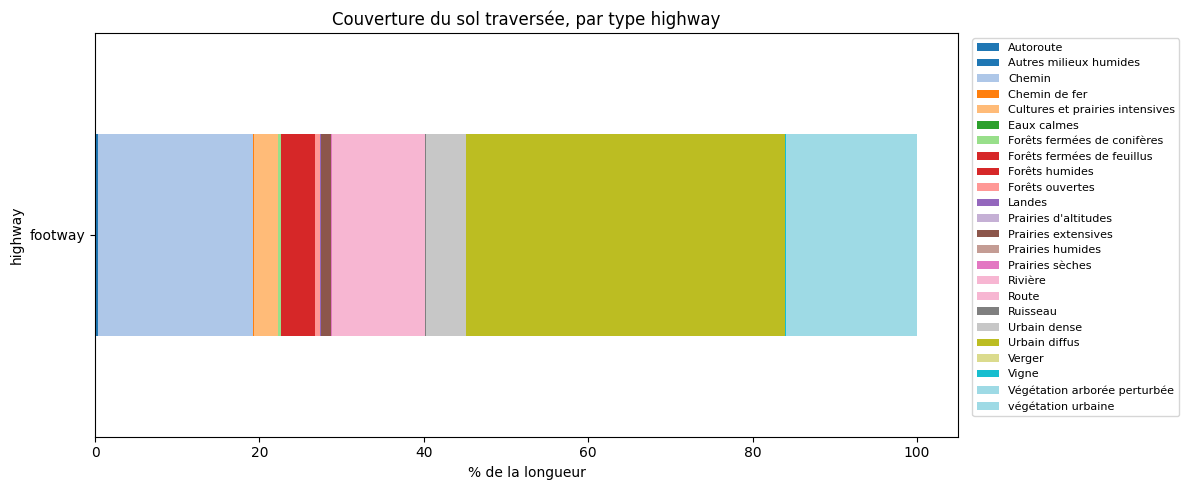

vegetation,Autoroute,Autres milieux humides,Chemin,Chemin de fer,Cultures et prairies intensives,Eaux calmes,Forêts fermées de conifères,Forêts fermées de feuillus,Forêts humides,Forêts ouvertes,Landes,Prairies d'altitudes,Prairies extensives,Prairies humides,Prairies sèches,Rivière,Route,Ruisseau,Urbain dense,Urbain diffus,Verger,Vigne,Végétation arborée perturbée,végétation urbaine
highway,,,,,,,,,,,,,,,,,,,,,,,,
footway,0.1,0.2,18.9,0.1,2.9,0.0,0.4,3.8,0.3,0.6,0.1,0.0,1.2,0.0,0.1,0.5,10.8,0.1,4.9,38.8,0.0,0.1,2.0,14.0


In [13]:
# Ventilation par type highway (part de la longueur, en %)
lg = long_seg.merge(seg_A[["segment_id", "highway"]], on="segment_id")
tab = lg.pivot_table(index="highway", columns=VEG_ATTR, values="length", aggfunc="sum", fill_value=0)
tab_pct = 100 * tab.div(tab.sum(axis=1), axis=0)

ax = tab_pct.plot.barh(stacked=True, figsize=(12, 5), colormap="tab20")
ax.set_xlabel("% de la longueur")
ax.set_title("Couverture du sol traversée, par type highway")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()
tab_pct.round(1)

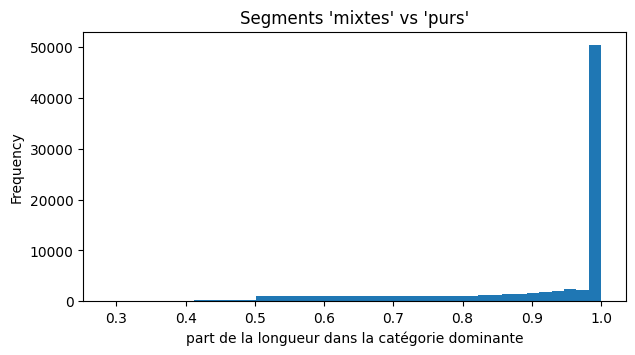

8.5% des segments ont moins de 60 % dans leur catégorie dominante


In [14]:
# Fiabilité de la catégorie dominante : quelle part du segment elle représente
ax = seg_A["part_dominante"].plot.hist(bins=40, figsize=(7, 3.5))
ax.set_xlabel("part de la longueur dans la catégorie dominante")
ax.set_title("Segments 'mixtes' vs 'purs'")
plt.show()
print(f"{(seg_A['part_dominante'] < 0.6).mean():.1%} des segments ont moins de 60 % dans leur catégorie dominante")

## 9. Extraction du contenu des rectangles

Pour chaque rectangle : surface (m²) et part (%) de chaque catégorie de couverture du sol.
C'est la base du futur proxy de largeur.

In [15]:
surf = intersection_par_categorie(rect_A, veg, VEG_ATTR, "area")

surf_large = surf.pivot_table(index="segment_id", columns=VEG_ATTR, values="area", fill_value=0)
surf_large.columns = [f"m2_{c}" for c in surf_large.columns]

rect_A = rect_A.drop(columns=[c for c in rect_A.columns if c.startswith(("m2_", "pct_"))], errors="ignore")
rect_A = rect_A.merge(surf_large, left_on="segment_id", right_index=True, how="left")
cols_m2 = [c for c in rect_A.columns if c.startswith("m2_")]
rect_A[cols_m2] = rect_A[cols_m2].fillna(0)
rect_A["m2_hors_couverture"] = (rect_A["rect_area_m2"] - rect_A[cols_m2].sum(axis=1)).clip(lower=0)
cols_m2 = cols_m2 + ["m2_hors_couverture"]
for c in cols_m2:
    rect_A["pct_" + c[3:]] = 100 * rect_A[c] / rect_A["rect_area_m2"]

rect_A[["segment_id", "highway", "rect_area_m2"] + cols_m2].head()

,segment_id,highway,rect_area_m2,m2_Autoroute,m2_Autres milieux humides,m2_Chemin,m2_Chemin de fer,m2_Cultures et prairies intensives,m2_Eaux calmes,m2_Forêts fermées de conifères,m2_Forêts fermées de feuillus,m2_Forêts humides,m2_Forêts ouvertes,m2_Glarier,m2_Graviere,m2_Landes,m2_Prairies d'altitudes,m2_Prairies extensives,m2_Prairies humides,m2_Prairies sèches,m2_Rivière,m2_Route,m2_Ruisseau,m2_Urbain dense,m2_Urbain diffus,m2_Verger,m2_Vigne,m2_Végétation arborée perturbée,m2_végétation urbaine,m2_hors_couverture
0,000000,footway,35.521171,0.0,0.0,1.599151,0.0,0.000000,0.0,0.0,33.922020,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.00000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,1.008786e-09
41,000041,footway,51.207534,0.0,0.0,13.192555,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,14.13549,0.0,0.0,0.0,0.0,0.0,23.879489,0.0,4.315623e-10
42,000042,footway,300.000000,0.0,0.0,99.679037,0.0,122.624348,0.0,0.0,31.758802,23.056728,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.452046,0.0,0.00000,0.0,0.0,0.0,0.0,0.0,17.429040,0.0,6.806999e-10
43,000043,footway,300.000000,0.0,0.0,100.193492,0.0,72.549471,0.0,0.0,81.308214,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.00000,0.0,0.0,0.0,0.0,0.0,45.948823,0.0,0.000000e+00
44,000044,footway,300.000000,0.0,0.0,19.211928,0.0,0.000000,0.0,0.0,136.548624,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.00000,0.0,0.0,0.0,0.0,0.0,144.239448,0.0,0.000000e+00


## 10. Exports

In [16]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
suffixe = f"{METHODE}_{LARGEUR_M:g}m"

rect_A.to_file(OUTPUT_DIR / f"rectangles_{suffixe}.gpkg", layer="rectangles", driver="GPKG")
seg_A.to_file(OUTPUT_DIR / f"segments_A_{suffixe}.gpkg", layer="segments_A", driver="GPKG")
seg_B.to_file(OUTPUT_DIR / "segments_B_scores_directs.gpkg", layer="segments_B", driver="GPKG")
long_seg.to_csv(OUTPUT_DIR / f"segments_longueur_par_categorie_{suffixe}.csv", index=False)
print("Exports dans", OUTPUT_DIR.resolve())

Exports dans /Users/maximiliantrique/Documents/GitHub/projet_pieton_gg/outputs/walk/largeur_trottoir


## 11. À COMPLÉTER — proxy de largeur de trottoir

Pistes :

- choisir les catégories de `vegetation` qui représentent une surface marchable (revêtement dur, etc.) ;
- proxy = surface marchable dans le rectangle / longueur du segment → largeur moyenne équivalente (m) ;
- tester plusieurs `LARGEUR_M` et comparer la stabilité du proxy ;
- convertir en score, puis réunir avec `seg_B["score_largeur"]`.

In [17]:
# CATEGORIES_MARCHABLES = [...]
# cols = [f"m2_{c}" for c in CATEGORIES_MARCHABLES if f"m2_{c}" in rect_A]
# rect_A["largeur_equiv_m"] = rect_A[cols].sum(axis=1) / rect_A["seg_len_m"]